# Alaga · Risco de alagamento por subprefeitura (São Paulo)

**Integrantes:** Eduardo Dallabella Lima (RM556803) · Guilherme Abe (RM554743) · Gustavo Ruiz Vieira Paulino (RM554779) · Heloísa Real (RM554535) · Victor Pacifico Dias (RM558017)

## 1. Problema

In [1]:
# Bibliotecas
import warnings, json, itertools, time
warnings.filterwarnings('ignore')
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from xgboost import XGBClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import (average_precision_score, roc_auc_score, f1_score, precision_score,
                             recall_score, brier_score_loss, confusion_matrix, precision_recall_curve,
                             roc_curve, ConfusionMatrixDisplay)

SEED = 42                      # semente fixa: resultados reproduzíveis
np.random.seed(SEED)
DADOS = Path('dados'); FIG = Path('figuras'); MOD = Path('modelo')
FIG.mkdir(exist_ok=True); MOD.mkdir(exist_ok=True)
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.dpi'] = 110

def salvar(nome):
    # salva cada gráfico em figuras/ (usados no relatório)
    plt.tight_layout(); plt.savefig(FIG / f'{nome}.png', dpi=130, bbox_inches='tight')

## 2. Dados reais

### 2.1 Ocorrências do CGE

In [2]:
# Pontos de alagamento registrados pelo CGE (1 linha = 1 ponto alagado)
# Fonte: cgesp.org/v3/alagamentos.jsp, extraído dia a dia (github.com/yssgor/sp-alagamentos)
occ = pd.read_csv(DADOS / 'ocorrencias_cge_2005_2026.csv', parse_dates=['data'])
print('Formato:', occ.shape)
print('Período bruto:', occ.data.min().date(), '→', occ.data.max().date())
print('Subprefeituras:', occ.subprefeitura.nunique(), '| Zonas:', occ.zona.nunique())

# Limpeza: o mesmo ponto às vezes aparece 2x na extração -> remove pelo id
print('IDs duplicados:', occ.id.duplicated().sum())
occ = occ.drop_duplicates('id')
print('Após remover duplicatas:', occ.shape)
occ[['data','inicio','fim','zona','subprefeitura','local','referencia','intransitavel']].head()

Formato: (19589, 16)
Período bruto: 2005-01-03 → 2026-10-29
Subprefeituras: 32 | Zonas: 6
IDs duplicados: 15
Após remover duplicatas: (19574, 16)


,data,inicio,fim,zona,subprefeitura,local,referencia,intransitavel
0,2005-01-03,2005-01-03T20:08:00-02:00,2005-01-04T01:47:00-02:00,Zona Norte,Pirituba/Jaraguá,MARGINAL TIETE,PTE. VELHA FEPASA - 50M APÓS,False
1,2005-01-03,2005-01-03T20:29:00-02:00,2005-01-04T00:12:00-02:00,Zona Norte,Pirituba/Jaraguá,MARGINAL TIETE,AV. ALEXANDRE COLARES,False
2,2005-01-03,2005-01-03T20:01:00-02:00,2005-01-03T22:15:00-02:00,Centro,Sé,AV. PRESTES MAIA,PASSARELA DAS NOIVAS - 100M ANTES,False
3,2005-01-03,2005-01-03T19:35:00-02:00,2005-01-03T22:18:00-02:00,Zona Oeste,Butantã,AV. EUSEBIO MATOSO,PC. JORGE DE LIMA,False
4,2005-01-03,2005-01-03T19:37:00-02:00,2005-01-03T20:54:00-02:00,Zona Oeste,Butantã,PTE. BERNARDO GOLDFARB,PC. JORGE DE LIMA,False


### 2.2 Chuva e tempo do INMET (A701)

In [3]:
# Série diária exportada do BDMEP/INMET (separador ';', 10 linhas de cabeçalho, faltante = 'null')
met = pd.read_csv(DADOS / 'dados_A701_D_2006-07-24_2025-04-25.csv', sep=';', skiprows=10, na_values='null')
met = met.iloc[:, :5]
met.columns = ['data', 'chuva', 'temp', 'umid', 'vento']   # chuva em mm, temp °C, umidade %, vento m/s
met['data'] = pd.to_datetime(met['data'])
print('Formato:', met.shape, '| Período:', met.data.min().date(), '→', met.data.max().date())
print('Datas duplicadas:', met.data.duplicated().sum())
print('\nProporção de valores faltantes:'); print(met.isna().mean().round(4))
met.describe().round(2)

Formato: (6851, 5) | Período: 2006-07-24 → 2025-04-25
Datas duplicadas: 0

Proporção de valores faltantes:
data     0.0000
chuva    0.0118
temp     0.0102
umid     0.0047
vento    0.0090
dtype: float64


,data,chuva,temp,umid,vento
count,6851,6770.00,6781.00,6819.00,6789.0
mean,2015-12-09 00:00:00,4.45,20.50,69.99,1.9
min,2006-07-24 00:00:00,0.00,8.00,23.30,0.0
25%,2011-04-01 12:00:00,0.00,18.30,64.10,1.5
50%,2015-12-09 00:00:00,0.00,20.80,71.10,1.9
75%,2020-08-16 12:00:00,2.40,23.00,77.40,2.3
max,2025-04-25 00:00:00,125.60,31.00,98.90,5.6
std,NaN,11.10,3.36,10.93,0.7


### 2.3 Alinhamento de datas INMET × CGE

In [4]:
# O CGE usa o dia local; o total diário do INMET pode estar em outra janela (UTC).
# Teste: correlação entre nº de alagamentos do dia e a chuva do INMET no dia anterior, mesmo dia e dia seguinte.
n_dia = occ.groupby('data').size().reindex(met.data).fillna(0).values
r = met.chuva.values
alin = {}
for desloc, nome in [(-1, 'INMET do dia anterior'), (0, 'INMET do mesmo dia'), (1, 'INMET do dia seguinte')]:
    rr = np.roll(r, -desloc); ok = ~np.isnan(r) & ~np.isnan(rr)
    ok[[0, -1]] = False
    alin[nome] = np.corrcoef(n_dia[ok], rr[ok])[0, 1]
print(pd.Series(alin, name='correlação com nº de pontos CGE').round(3))
print()

# Prova com um evento real: o temporal de 24/01/2025
print('Evento de 24/01/2025 (temporal com dezenas de pontos):')
ev = met[(met.data >= '2025-01-23') & (met.data <= '2025-01-26')][['data', 'chuva']].copy()
ev['pontos_CGE_no_mesmo_rótulo'] = ev.data.map(occ.groupby('data').size()).fillna(0).astype(int)
print(ev.to_string(index=False))

INMET do dia anterior    0.118
INMET do mesmo dia       0.341
INMET do dia seguinte    0.579
Name: correlação com nº de pontos CGE, dtype: float64

Evento de 24/01/2025 (temporal com dezenas de pontos):
      data  chuva  pontos_CGE_no_mesmo_rótulo
2025-01-23   13.4                           1
2025-01-24    0.0                          39
2025-01-25  125.6                           3
2025-01-26    3.4                          16


In [5]:
# Resultado: a chuva rotulada d+1 no INMET explica os alagamentos do dia d (0,58 vs 0,34),
# e o temporal de 24/01 aparece no INMET em 25/01.
# Correção: desloca o INMET em -1 dia ANTES de cruzar as bases (senão o modelo aprende com a chuva errada).
met['data'] = met['data'] - pd.Timedelta(days=1)
print('INMET realinhado ao dia local:', met.data.min().date(), '→', met.data.max().date())

INMET realinhado ao dia local: 2006-07-23 → 2025-04-24


## 3. Análise exploratória

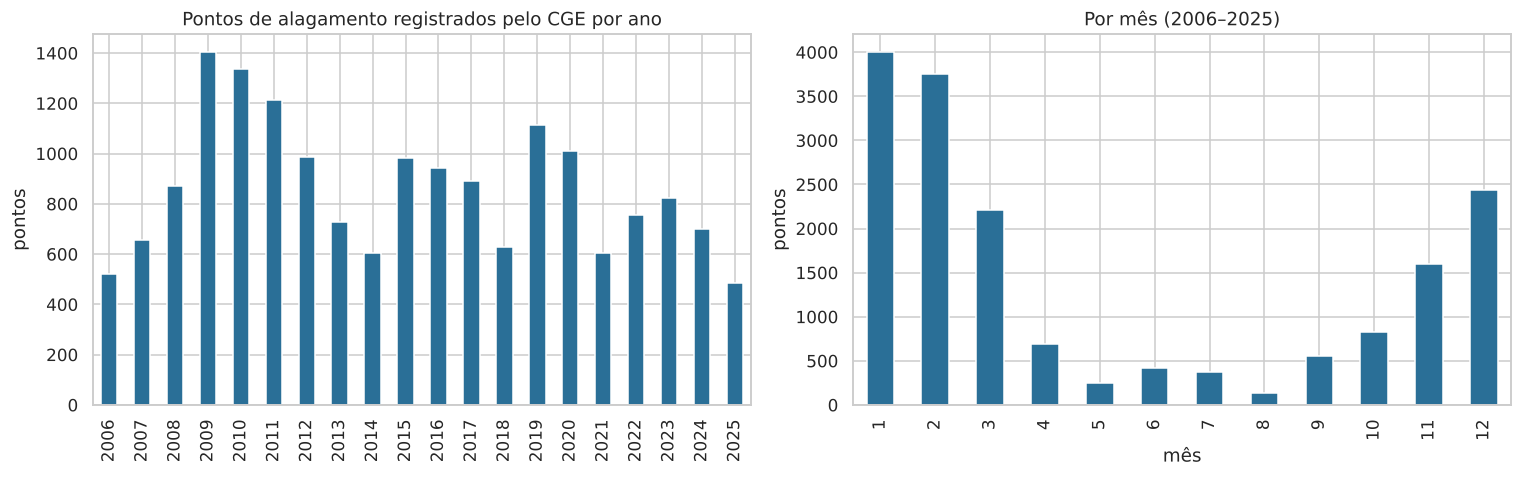

In [6]:
# Período em comum entre as duas bases
INI, FIM = pd.Timestamp('2006-08-01'), pd.Timestamp('2025-04-24')
o = occ[(occ.data >= INI) & (occ.data <= FIM)]

# Alagamentos por ano e por mês: concentração no verão (dez–mar)
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
o.groupby(o.data.dt.year).size().plot.bar(ax=ax[0], color='#2a6f97')
ax[0].set_title('Pontos de alagamento registrados pelo CGE por ano'); ax[0].set_xlabel(''); ax[0].set_ylabel('pontos')
o.groupby(o.data.dt.month).size().plot.bar(ax=ax[1], color='#2a6f97')
ax[1].set_title('Por mês (2006–2025)'); ax[1].set_xlabel('mês'); ax[1].set_ylabel('pontos')
salvar('01_ocorrencias_ano_mes'); plt.show()

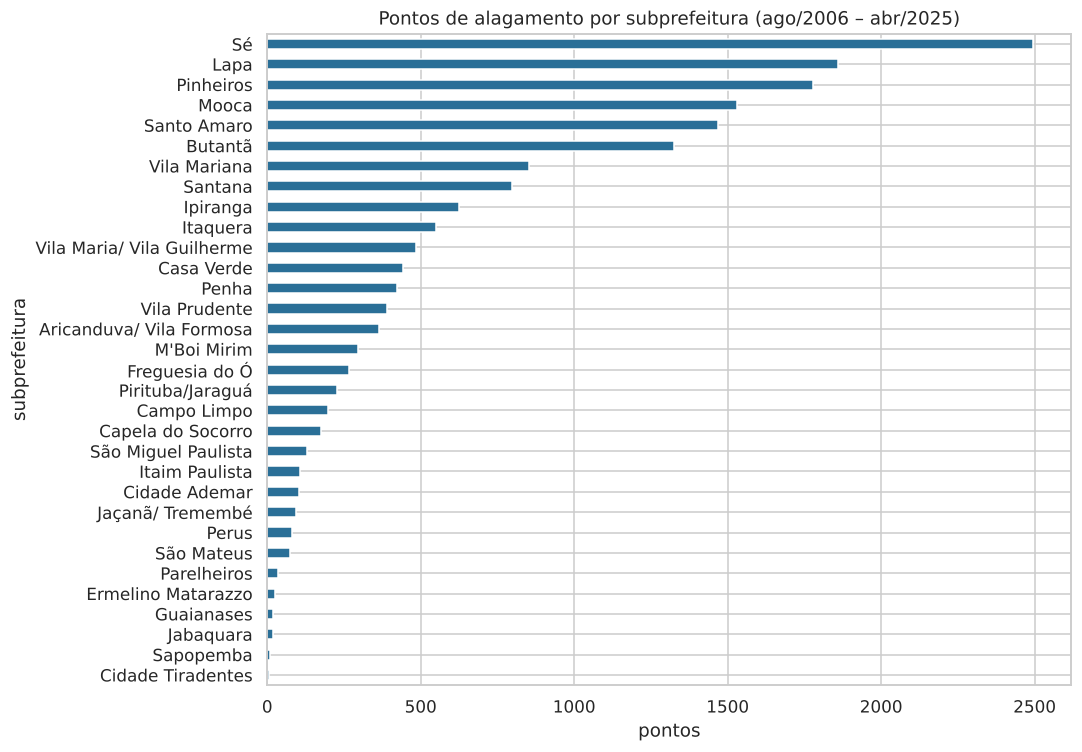

In [7]:
# Alagamentos por subprefeitura: a região importa muito (Sé, Pinheiros, Lapa, Mooca no topo)
top = o.subprefeitura.value_counts()
fig, ax = plt.subplots(figsize=(10, 7))
top.sort_values().plot.barh(ax=ax, color='#2a6f97')
ax.set_title('Pontos de alagamento por subprefeitura (ago/2006 – abr/2025)'); ax.set_xlabel('pontos')
salvar('02_ocorrencias_subprefeitura'); plt.show()

## 4. Preparação dos dados

In [8]:
# Atributos de chuva (o índice é a data, já realinhada)
m = met.sort_values('data').set_index('data').copy()
c = m['chuva']
m['chuva_d1'] = c.shift(1)                                         # chuva de ontem
m['chuva_d2'] = c.shift(2)                                         # chuva de anteontem
m['chuva_3d'] = c.rolling(3, min_periods=3).sum()                  # acumulado de 3 dias (inclui hoje)
m['chuva_ant_7d'] = c.shift(1).rolling(7, min_periods=6).sum()     # 7 dias ANTERIORES: solo encharcado
m['chuva_ant_30d'] = c.shift(1).rolling(30, min_periods=25).sum()  # 30 dias ANTERIORES: rios e galerias cheios
m = m.reset_index()

# Grade completa subprefeitura × dia: dias sem registro viram exemplos negativos (alagou = 0).
# Sem isso o modelo nunca veria o "não alagou".
subs = occ[['subprefeitura', 'zona']].drop_duplicates('subprefeitura').sort_values('subprefeitura')
grade = pd.DataFrame({'data': pd.date_range(INI, FIM)}).merge(subs, how='cross')
cont = occ.groupby(['data', 'subprefeitura']).size().rename('n_pontos').reset_index()
df = grade.merge(cont, on=['data', 'subprefeitura'], how='left').fillna({'n_pontos': 0})
df['alagou'] = (df.n_pontos > 0).astype(int)        # ALVO: 1 se teve >= 1 ponto no dia
df = df.merge(m, on='data', how='left')

# Limpeza: remove dias sem dado meteorológico (não imputamos chuva: seria inventar o atributo principal)
antes = len(df)
df = df.dropna(subset=['chuva', 'chuva_d1', 'chuva_d2', 'chuva_ant_7d', 'chuva_ant_30d', 'temp', 'umid', 'vento'])
print(f'Linhas removidas por falta de dado meteorológico: {antes - len(df)} ({(antes-len(df))/antes:.1%})')

# Sazonalidade como seno/cosseno: dezembro fica "perto" de janeiro
doy = df.data.dt.dayofyear
df['sazon_sin'] = np.sin(2 * np.pi * doy / 365.25)
df['sazon_cos'] = np.cos(2 * np.pi * doy / 365.25)
print('Base final:', df.shape, f'| taxa de dias com alagamento: {df.alagou.mean():.2%}')

Linhas removidas por falta de dado meteorológico: 9088 (4.2%)
Base final: (209856, 16) | taxa de dias com alagamento: 3.52%


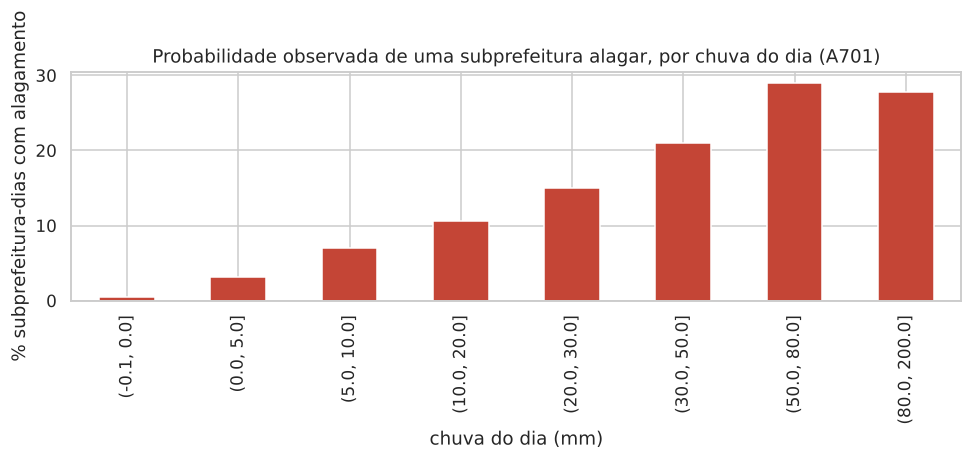

,% alagou,subpref-dias
faixa_chuva,,
"(-0.1, 0.0]",0.4,122784
"(0.0, 5.0]",3.2,45408
"(5.0, 10.0]",7.0,12160
"(10.0, 20.0]",10.6,13696
"(20.0, 30.0]",15.0,6912
"(30.0, 50.0]",20.9,6368
"(50.0, 80.0]",29.0,1984
"(80.0, 200.0]",27.8,544


In [9]:
# Sinal claro: quanto mais chuva no dia, maior a chance de a subprefeitura alagar
faixas = [-0.1, 0, 5, 10, 20, 30, 50, 80, 200]
t = df.assign(faixa_chuva=pd.cut(df.chuva, faixas)).groupby('faixa_chuva', observed=True).alagou.agg(['mean', 'size'])
fig, ax = plt.subplots(figsize=(9, 4))
(t['mean'] * 100).plot.bar(ax=ax, color='#c44536')
ax.set_title('Probabilidade observada de uma subprefeitura alagar, por chuva do dia (A701)')
ax.set_xlabel('chuva do dia (mm)'); ax.set_ylabel('% subprefeitura-dias com alagamento')
salvar('03_chuva_vs_alagamento'); plt.show()
t.assign(mean=lambda x: (x['mean']*100).round(1)).rename(columns={'mean': '% alagou', 'size': 'subpref-dias'})

### 4.1 Divisão treino / teste (temporal)

In [10]:
# Divisão por TEMPO, não aleatória: o app prevê o futuro, então o teste fica depois do treino.
# (Aleatória misturaria dias do mesmo temporal entre treino e teste e inflaria as métricas.)
CORTE = pd.Timestamp('2022-01-01')
treino = df[df.data < CORTE].copy()     # ago/2006 – dez/2021
teste = df[df.data >= CORTE].copy()     # jan/2022 – abr/2025 (nunca visto na seleção de hiperparâmetros)

# Atributos da região calculados SOMENTE com o treino (evita vazamento de dados do teste)
taxa_hist = treino.groupby('subprefeitura').alagou.mean().rename('taxa_hist_subpref')
pontos_hist = occ[(occ.data >= INI) & (occ.data < CORTE)].groupby('subprefeitura').ponto_id.nunique().rename('pontos_hist_subpref')
ZONAS = sorted(df.zona.unique())

def montar(d):
    # adiciona histórico da subprefeitura e zona em one-hot
    d = d.join(taxa_hist, on='subprefeitura').join(pontos_hist, on='subprefeitura')
    d['pontos_hist_subpref'] = d['pontos_hist_subpref'].fillna(0)
    for z in ZONAS:
        d['zona_' + z.replace(' ', '_')] = (d.zona == z).astype(int)
    return d
treino, teste = montar(treino), montar(teste)

FEATURES = ['chuva', 'chuva_d1', 'chuva_d2', 'chuva_3d', 'chuva_ant_7d', 'chuva_ant_30d',
            'temp', 'umid', 'vento', 'sazon_sin', 'sazon_cos',
            'taxa_hist_subpref', 'pontos_hist_subpref'] + ['zona_' + z.replace(' ', '_') for z in ZONAS]
X_tr, y_tr = treino[FEATURES], treino.alagou.values
X_te, y_te = teste[FEATURES], teste.alagou.values

resumo = pd.DataFrame({
    'período': [f'{treino.data.min().date()} → {treino.data.max().date()}', f'{teste.data.min().date()} → {teste.data.max().date()}'],
    'linhas': [len(treino), len(teste)],
    'dias com alagamento (positivos)': [y_tr.sum(), y_te.sum()],
    'taxa positiva': [f'{y_tr.mean():.2%}', f'{y_te.mean():.2%}']}, index=['treino', 'teste'])
print(len(FEATURES), 'atributos'); resumo

19 atributos


,período,linhas,dias com alagamento (positivos),taxa positiva
treino,2006-08-20 → 2021-12-31,174944,6072,3.47%
teste,2022-01-01 → 2025-04-24,34912,1317,3.77%


## 5. Escolha do modelo: XGBoost

## 6. Treino com diferentes hiperparâmetros + validação cruzada só no treino

In [11]:
# Validação cruzada TEMPORAL (janela crescente, 5 folds) dentro do treino:
# cada fold treina nos anos anteriores e valida no bloco seguinte. O teste não participa.
datas_tr = np.sort(treino.data.unique())
blocos = np.array_split(datas_tr, 6)
FOLDS = []
for i in range(1, 6):
    idx_a = np.where(treino.data.isin(np.concatenate(blocos[:i])))[0]
    idx_v = np.where(treino.data.isin(blocos[i]))[0]
    FOLDS.append((idx_a, idx_v))
    print(f'fold {i}: treina {pd.Timestamp(blocos[0][0]).date()}→{pd.Timestamp(blocos[i-1][-1]).date()} '
          f'| valida {pd.Timestamp(blocos[i][0]).date()}→{pd.Timestamp(blocos[i][-1]).date()}')

def novo_xgb(**p):
    # XGBoost com parâmetros fixos + os hiperparâmetros testados em **p
    return XGBClassifier(subsample=0.9, colsample_bytree=0.9, tree_method='hist', eval_metric='logloss',
                         n_jobs=-1, random_state=SEED, **p)

fold 1: treina 2006-08-20→2009-03-16 | valida 2009-03-17→2011-10-10
fold 2: treina 2006-08-20→2011-10-10 | valida 2011-10-11→2014-04-25
fold 3: treina 2006-08-20→2014-04-25 | valida 2014-04-26→2016-12-06
fold 4: treina 2006-08-20→2016-12-06 | valida 2016-12-07→2019-06-16
fold 5: treina 2006-08-20→2019-06-16 | valida 2019-06-17→2021-12-31


In [12]:
# 3 hiperparâmetros × 18 combinações:
#   max_depth     -> profundidade de cada árvore (complexidade)
#   learning_rate -> tamanho do passo de cada árvore nova
#   n_estimators  -> quantidade de árvores
# Métrica: PR-AUC. Com ~3,5% de positivos a acurácia engana (prever "nunca alaga" daria 96,5%);
# um modelo aleatório tem PR-AUC = taxa positiva (~0,035).
GRADE = list(itertools.product([3, 5, 8], [0.03, 0.1, 0.3], [100, 400]))
linhas = []
t0 = time.time()
for md_, lr_, ne_ in GRADE:
    ap_a, ap_v, auc_v = [], [], []
    for ia, iv in FOLDS:
        mdl = novo_xgb(max_depth=md_, learning_rate=lr_, n_estimators=ne_).fit(X_tr.iloc[ia], y_tr[ia])
        pa = mdl.predict_proba(X_tr.iloc[ia])[:, 1]; pv = mdl.predict_proba(X_tr.iloc[iv])[:, 1]
        ap_a.append(average_precision_score(y_tr[ia], pa))   # desempenho nos dados que ele viu
        ap_v.append(average_precision_score(y_tr[iv], pv))   # desempenho em anos seguintes
        auc_v.append(roc_auc_score(y_tr[iv], pv))
    linhas.append(dict(max_depth=md_, learning_rate=lr_, n_estimators=ne_,
                       pr_auc_treino_fold=np.mean(ap_a), pr_auc_validacao=np.mean(ap_v),
                       dp_validacao=np.std(ap_v), roc_auc_validacao=np.mean(auc_v)))
print(f'{len(GRADE)} combinações × {len(FOLDS)} folds = {len(GRADE)*len(FOLDS)} treinos em {time.time()-t0:.0f}s')

cv = pd.DataFrame(linhas)
cv['gap_overfitting'] = cv.pr_auc_treino_fold - cv.pr_auc_validacao   # gap grande = decorou o treino
cv = cv.sort_values('pr_auc_validacao', ascending=False).reset_index(drop=True)
cv.index += 1
cv.to_csv(FIG / 'resultados_validacao_cruzada.csv', index_label='rank')
cv.round(4)

18 combinações × 5 folds = 90 treinos em 107s


,max_depth,learning_rate,n_estimators,pr_auc_treino_fold,pr_auc_validacao,dp_validacao,roc_auc_validacao,gap_overfitting
1,5,0.03,100,0.5178,0.3731,0.0406,0.9256,0.1447
2,5,0.03,400,0.6413,0.3688,0.0381,0.9255,0.2726
3,3,0.03,400,0.5185,0.3676,0.0364,0.9268,0.1508
4,3,0.03,100,0.4439,0.3647,0.0432,0.9249,0.0792
5,5,0.10,100,0.6143,0.3627,0.0344,0.9243,0.2516
6,8,0.03,100,0.6683,0.3627,0.0416,0.9230,0.3057
7,3,0.10,100,0.5018,0.3610,0.0359,0.9264,0.1408
8,8,0.03,400,0.8350,0.3564,0.0383,0.9228,0.4787
9,8,0.10,100,0.8007,0.3513,0.0399,0.9225,0.4494
10,3,0.10,400,0.6130,0.3479,0.0360,0.9236,0.2651


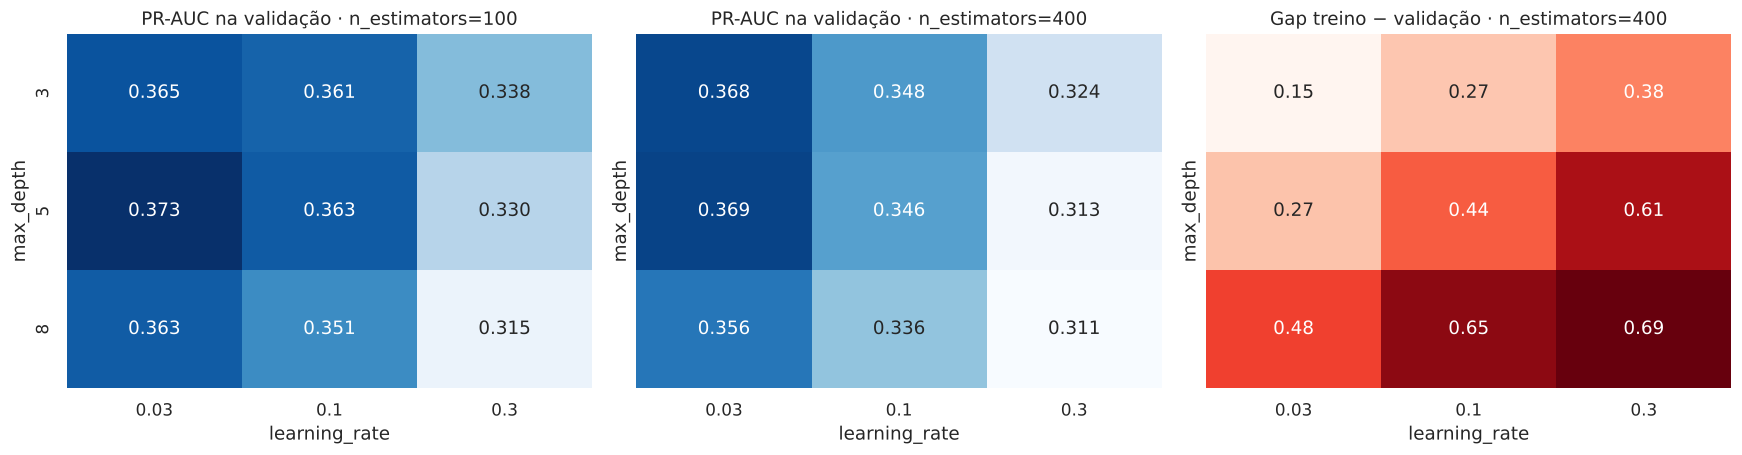

In [13]:
# Heatmaps: PR-AUC na validação por combinação e o gap treino − validação
fig, ax = plt.subplots(1, 3, figsize=(16, 4.3), sharey=True)
for a, ne_ in zip(ax[:2], [100, 400]):
    piv = cv[cv.n_estimators == ne_].pivot(index='max_depth', columns='learning_rate', values='pr_auc_validacao')
    sns.heatmap(piv, annot=True, fmt='.3f', cmap='Blues', ax=a, cbar=False, vmin=cv.pr_auc_validacao.min(), vmax=cv.pr_auc_validacao.max())
    a.set_title(f'PR-AUC na validação · n_estimators={ne_}')
piv = cv[cv.n_estimators == 400].pivot(index='max_depth', columns='learning_rate', values='gap_overfitting')
sns.heatmap(piv, annot=True, fmt='.2f', cmap='Reds', ax=ax[2], cbar=False)
ax[2].set_title('Gap treino − validação · n_estimators=400')
salvar('04_grid_hiperparametros'); plt.show()

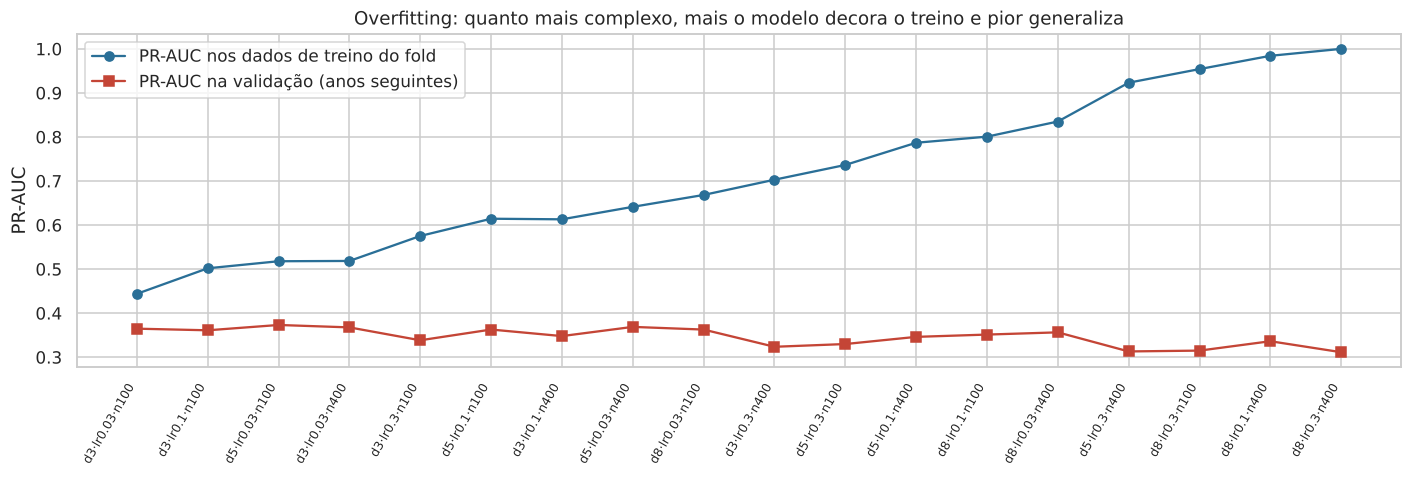

In [14]:
# Overfitting: os modelos mais complexos chegam a PR-AUC ~1,0 no treino (decoraram)
# e são os PIORES na validação. Os rasos e com aprendizado lento generalizam melhor.
o_ = cv.sort_values('gap_overfitting').reset_index(drop=True)
fig, ax = plt.subplots(figsize=(13, 4.5))
x = np.arange(len(o_))
ax.plot(x, o_.pr_auc_treino_fold, 'o-', label='PR-AUC nos dados de treino do fold', color='#2a6f97')
ax.plot(x, o_.pr_auc_validacao, 's-', label='PR-AUC na validação (anos seguintes)', color='#c44536')
ax.set_xticks(x); ax.set_xticklabels([f'd{r.max_depth}·lr{r.learning_rate}·n{r.n_estimators}' for r in o_.itertuples()], rotation=60, ha='right', fontsize=8)
ax.set_title('Overfitting: quanto mais complexo, mais o modelo decora o treino e pior generaliza')
ax.set_ylabel('PR-AUC'); ax.legend()
salvar('05_overfitting_combinacoes'); plt.show()

### 6.1 Modelo final e limiar de decisão

In [15]:
# Melhor combinação = maior PR-AUC média na validação
melhor = cv.iloc[0]
PARAMS = dict(max_depth=int(melhor.max_depth), learning_rate=float(melhor.learning_rate), n_estimators=int(melhor.n_estimators))
print('Melhores hiperparâmetros (PR-AUC média na validação):', PARAMS)

# Limiar do alerta (sim/não): o que maximiza o F1 nas previsões fora-da-amostra dos folds.
# Escolhido sem olhar o teste.
oof_y, oof_p = [], []
for ia, iv in FOLDS:
    mdl = novo_xgb(**PARAMS).fit(X_tr.iloc[ia], y_tr[ia])
    oof_y.append(y_tr[iv]); oof_p.append(mdl.predict_proba(X_tr.iloc[iv])[:, 1])
oof_y, oof_p = np.concatenate(oof_y), np.concatenate(oof_p)
pr, rc, th = precision_recall_curve(oof_y, oof_p)
f1s = 2 * pr * rc / (pr + rc + 1e-12)
LIMIAR = float(th[np.argmax(f1s[:-1])])
print(f'Limiar que maximiza o F1 na validação: {LIMIAR:.3f}')

# Modelo final: treinado com TODO o período de treino
modelo = novo_xgb(**PARAMS).fit(X_tr, y_tr)
p_tr = modelo.predict_proba(X_tr)[:, 1]
p_te = modelo.predict_proba(X_te)[:, 1]

Melhores hiperparâmetros (PR-AUC média na validação): {'max_depth': 5, 'learning_rate': 0.03, 'n_estimators': 100}


Limiar que maximiza o F1 na validação: 0.171


## 7. Resultados em treino e teste

In [16]:
def metricas(y, p, lim):
    # métricas de ranking (PR-AUC, ROC-AUC), de decisão (precisão, recall, F1) e de probabilidade (Brier)
    yh = (p >= lim).astype(int)
    return {'PR-AUC (Average Precision)': average_precision_score(y, p), 'ROC-AUC': roc_auc_score(y, p),
            'Precisão': precision_score(y, yh, zero_division=0), 'Recall (sensibilidade)': recall_score(y, yh),
            'F1': f1_score(y, yh), 'Brier (menor = melhor)': brier_score_loss(y, p),
            'Taxa positiva (referência p/ PR-AUC)': y.mean()}

# Referência 1: regra simples "alerta se chover >= 30 mm"
base_regra = lambda d: (d.chuva >= 30).astype(float).values
# Referência 2: Regressão Logística com os mesmos atributos (limiar pelo melhor F1 no treino)
logit = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, class_weight=None)).fit(X_tr, y_tr)
pl_tr, pl_te = logit.predict_proba(X_tr)[:, 1], logit.predict_proba(X_te)[:, 1]
pr_l, rc_l, th_l = precision_recall_curve(y_tr, pl_tr)
lim_l = float(th_l[np.argmax((2*pr_l*rc_l/(pr_l+rc_l+1e-12))[:-1])])

# Tabela lado a lado: XGBoost treino × teste + referências no teste
tab = pd.DataFrame({
    'XGBoost · treino': metricas(y_tr, p_tr, LIMIAR),
    'XGBoost · teste': metricas(y_te, p_te, LIMIAR),
    'Reg. Logística · teste': metricas(y_te, pl_te, lim_l),
    'Regra chuva≥30mm · teste': metricas(y_te, base_regra(teste), 0.5),
}).round(3)
tab.to_csv(FIG / 'metricas_treino_teste.csv')
tab

,XGBoost · treino,XGBoost · teste,Reg. Logística · teste,Regra chuva≥30mm · teste
PR-AUC (Average Precision),0.450,0.335,0.295,0.100
ROC-AUC,0.946,0.917,0.878,0.640
Precisão,0.371,0.310,0.321,0.232
Recall (sensibilidade),0.597,0.528,0.415,0.321
F1,0.457,0.391,0.362,0.269
Brier (menor = melhor),0.025,0.029,0.031,0.066
Taxa positiva (referência p/ PR-AUC),0.035,0.038,0.038,0.038


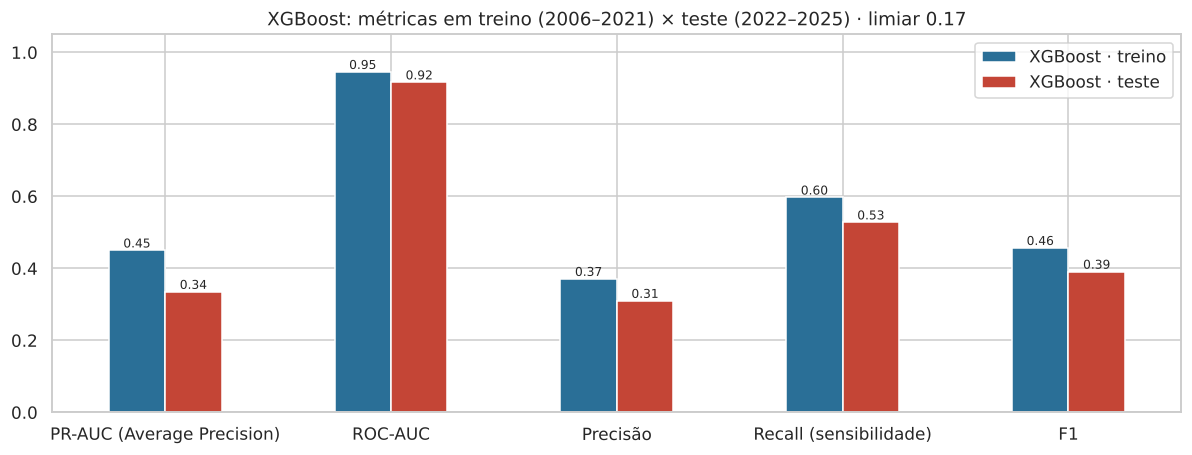

In [17]:
# Gráfico treino × teste: a queda é moderada -> o modelo generaliza
sel = ['PR-AUC (Average Precision)', 'ROC-AUC', 'Precisão', 'Recall (sensibilidade)', 'F1']
fig, ax = plt.subplots(figsize=(11, 4.3))
tab.loc[sel, ['XGBoost · treino', 'XGBoost · teste']].plot.bar(ax=ax, color=['#2a6f97', '#c44536'], rot=0)
for cnt in ax.containers: ax.bar_label(cnt, fmt='%.2f', fontsize=8)
ax.set_title(f'XGBoost: métricas em treino (2006–2021) × teste (2022–2025) · limiar {LIMIAR:.2f}')
ax.set_ylim(0, 1.05)
salvar('06_metricas_treino_teste'); plt.show()

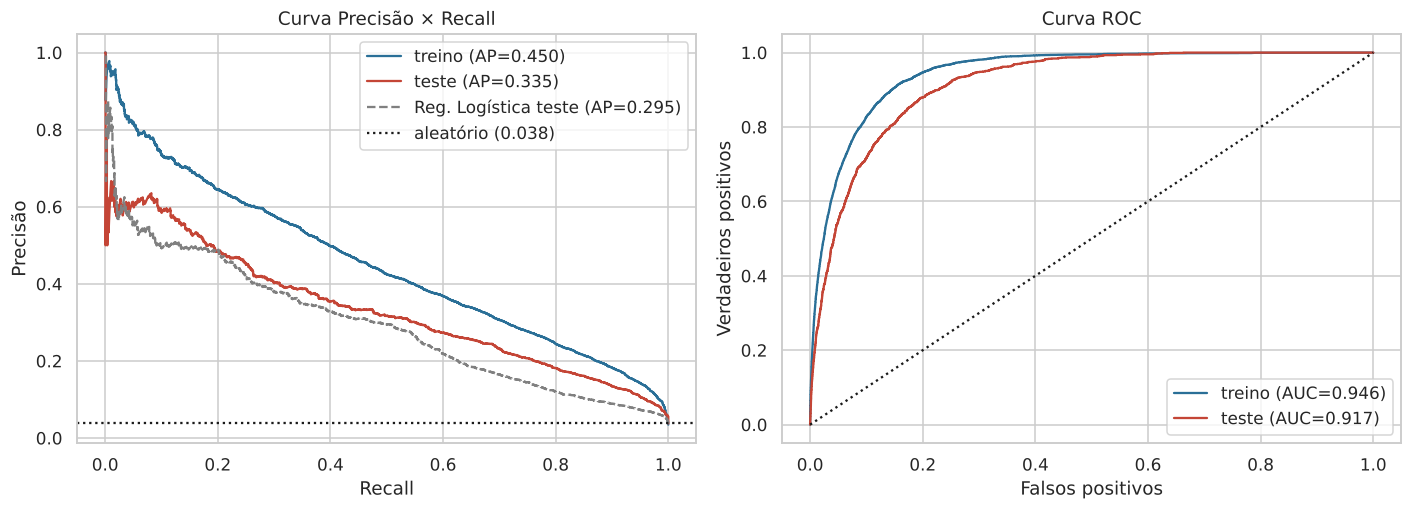

In [18]:
# Curvas Precisão×Recall e ROC em treino e teste (linha pontilhada = modelo aleatório)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
for y, p, nome, cor in [(y_tr, p_tr, 'treino', '#2a6f97'), (y_te, p_te, 'teste', '#c44536')]:
    pr_, rc_, _ = precision_recall_curve(y, p); ax[0].plot(rc_, pr_, label=f'{nome} (AP={average_precision_score(y, p):.3f})', color=cor)
    fpr, tpr, _ = roc_curve(y, p); ax[1].plot(fpr, tpr, label=f'{nome} (AUC={roc_auc_score(y, p):.3f})', color=cor)
pr_, rc_, _ = precision_recall_curve(y_te, pl_te); ax[0].plot(rc_, pr_, '--', color='gray', label=f'Reg. Logística teste (AP={average_precision_score(y_te, pl_te):.3f})')
ax[0].axhline(y_te.mean(), ls=':', color='k', label=f'aleatório ({y_te.mean():.3f})')
ax[1].plot([0, 1], [0, 1], ':', color='k')
ax[0].set(title='Curva Precisão × Recall', xlabel='Recall', ylabel='Precisão'); ax[0].legend()
ax[1].set(title='Curva ROC', xlabel='Falsos positivos', ylabel='Verdadeiros positivos'); ax[1].legend()
salvar('07_curvas_pr_roc'); plt.show()

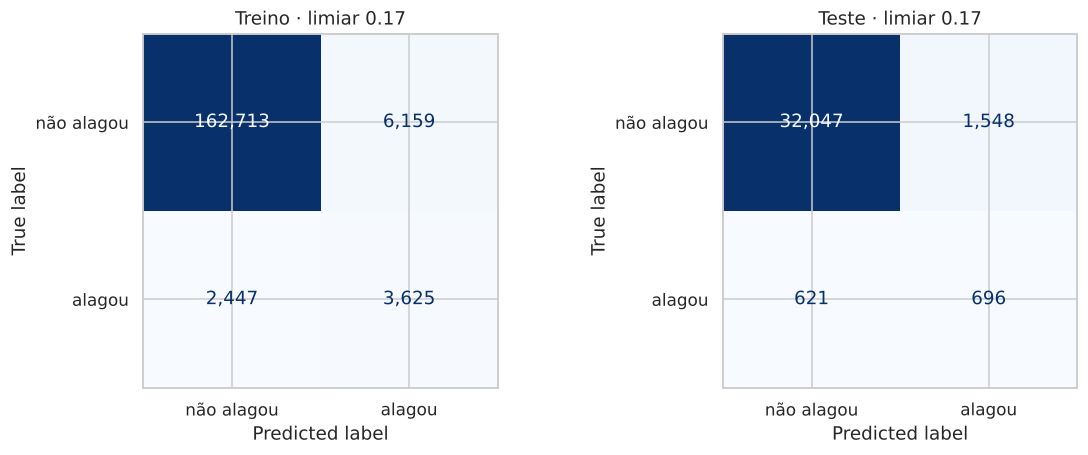

In [19]:
# Matrizes de confusão com o limiar escolhido
fig, ax = plt.subplots(1, 2, figsize=(11, 4.3))
for a, y, p, nome in [(ax[0], y_tr, p_tr, 'Treino'), (ax[1], y_te, p_te, 'Teste')]:
    ConfusionMatrixDisplay(confusion_matrix(y, (p >= LIMIAR).astype(int)), display_labels=['não alagou', 'alagou']).plot(ax=a, cmap='Blues', colorbar=False, values_format=',')
    a.set_title(f'{nome} · limiar {LIMIAR:.2f}')
salvar('08_matriz_confusao'); plt.show()

### 7.1 Curva de aprendizado (overfitting do modelo escolhido)

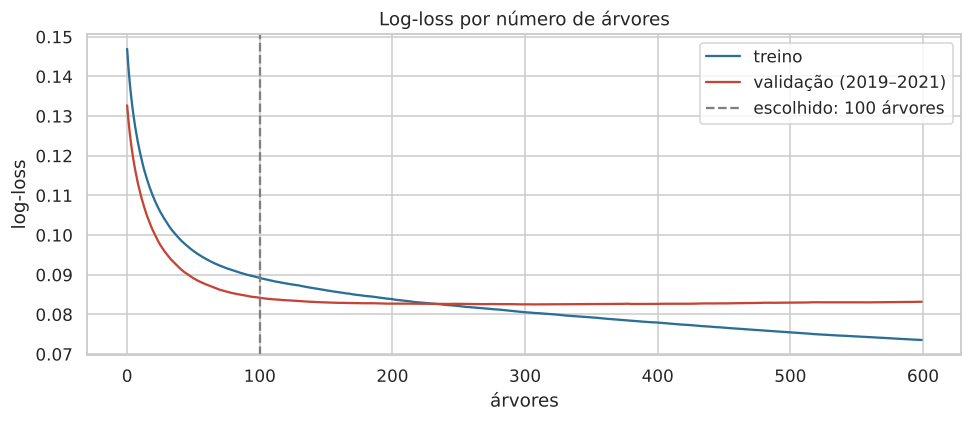

In [20]:
# Treina até 600 árvores e acompanha a perda no treino e no último bloco de validação (2019–2021).
# O treino cai sempre; a validação estabiliza e depois piora -> ali começa o overfitting.
ia, iv = FOLDS[-1]
diag = novo_xgb(max_depth=PARAMS['max_depth'], learning_rate=PARAMS['learning_rate'], n_estimators=600)
diag.fit(X_tr.iloc[ia], y_tr[ia], eval_set=[(X_tr.iloc[ia], y_tr[ia]), (X_tr.iloc[iv], y_tr[iv])], verbose=False)
ev = diag.evals_result()
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(ev['validation_0']['logloss'], label='treino', color='#2a6f97')
ax.plot(ev['validation_1']['logloss'], label='validação (2019–2021)', color='#c44536')
ax.axvline(PARAMS['n_estimators'], ls='--', color='gray', label=f"escolhido: {PARAMS['n_estimators']} árvores")
ax.set(title='Log-loss por número de árvores', xlabel='árvores', ylabel='log-loss'); ax.legend()
salvar('09_curva_aprendizado'); plt.show()

## 8. Faixa de risco do app (baixo / moderado / elevado)

In [21]:
# Cortes fixados olhando só o treino (taxa média ~3,5%):
#   baixo < 10%  |  moderado 10–40%  |  elevado >= 40%
# Verificação: com que frequência ALAGOU DE FATO em cada faixa, no treino e no teste.
CORTES = [0, 0.10, 0.40, 1.0]; ROTULOS = ['baixo', 'moderado', 'elevado']
def faixa(p): return pd.cut(p, CORTES, labels=ROTULOS, include_lowest=True)
calib = []
for nome, d, p in [('treino', treino, p_tr), ('teste', teste, p_te)]:
    g = pd.DataFrame({'faixa': faixa(p), 'alagou': d.alagou.values}).groupby('faixa', observed=False).alagou
    calib.append(pd.DataFrame({'subpref-dias': g.size(), '% do total': (g.size() / len(d) * 100).round(1),
                               '% que alagou de fato': (g.mean() * 100).round(1)}).assign(conjunto=nome))
calib = pd.concat(calib).reset_index().set_index(['conjunto', 'faixa'])
calib.to_csv(FIG / 'faixas_risco.csv')
calib

subpref-dias  % do total  % que alagou de fato
conjunto faixa                                                   
treino   baixo           158170        90.4                   0.9
         moderado         14276         8.2                  21.5
         elevado           2498         1.4                  60.5
teste    baixo            31086        89.0                   1.3
         moderado          3208         9.2                  19.4
         elevado            618         1.8                  46.9

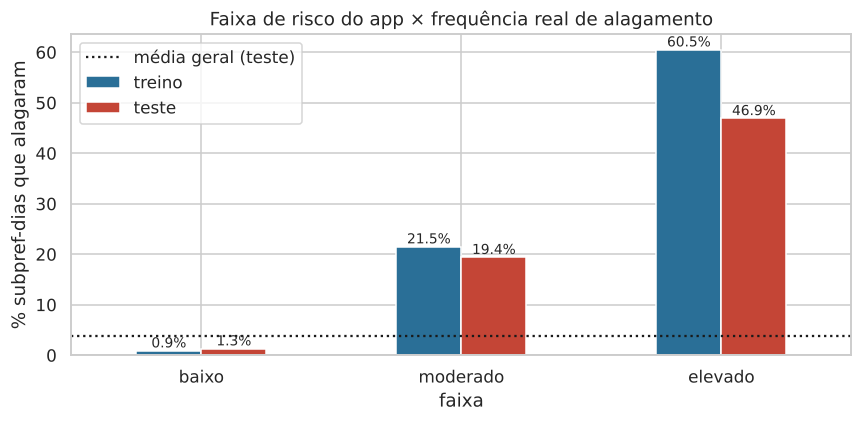

In [22]:
c2 = calib.reset_index().pivot(index='faixa', columns='conjunto', values='% que alagou de fato').loc[ROTULOS]
fig, ax = plt.subplots(figsize=(8, 4))
c2[['treino', 'teste']].plot.bar(ax=ax, color=['#2a6f97', '#c44536'], rot=0)
for cnt in ax.containers: ax.bar_label(cnt, fmt='%.1f%%', fontsize=9)
ax.axhline(y_te.mean() * 100, ls=':', color='k', label='média geral (teste)')
ax.set(title='Faixa de risco do app × frequência real de alagamento', xlabel='faixa', ylabel='% subpref-dias que alagaram'); ax.legend()
salvar('10_faixas_risco'); plt.show()

## 9. O que o modelo aprendeu

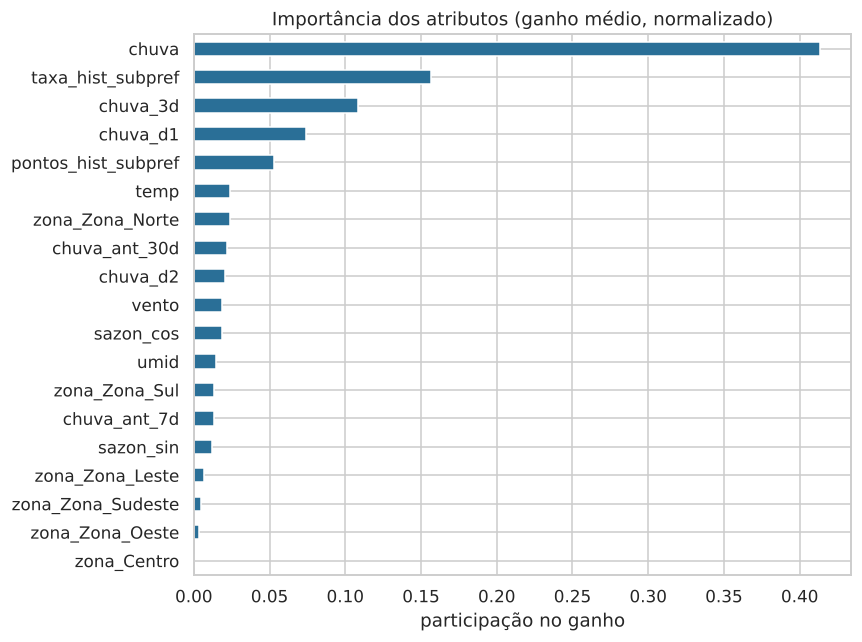

chuva                  0.413
taxa_hist_subpref      0.156
chuva_3d               0.108
chuva_d1               0.074
pontos_hist_subpref    0.053
temp                   0.024
zona_Zona_Norte        0.024
chuva_ant_30d          0.022
chuva_d2               0.020
vento                  0.018
dtype: float64

In [23]:
# Importância por ganho: quanto cada atributo ajudou a separar "alagou" de "não alagou"
imp = pd.Series(modelo.get_booster().get_score(importance_type='gain')).reindex(FEATURES).fillna(0)
imp = (imp / imp.sum()).sort_values()
fig, ax = plt.subplots(figsize=(8, 6))
imp.plot.barh(ax=ax, color='#2a6f97')
ax.set(title='Importância dos atributos (ganho médio, normalizado)', xlabel='participação no ganho')
salvar('11_importancia_atributos'); plt.show()
imp.sort_values(ascending=False).round(3).head(10)

## 10. Exemplo real: o dia mais chuvoso do teste

In [24]:
# O que o app mostraria por subprefeitura × o que o CGE realmente registrou
dia = teste.loc[teste.chuva.idxmax(), 'data']
ex = teste[teste.data == dia].assign(prob=p_te[teste.data.values == dia])
ex['risco_app'] = faixa(ex.prob.values)
print(f"Dia {dia.date()} · chuva A701 = {ex.chuva.iloc[0]:.1f} mm · acumulado 7 dias antes = {ex.chuva_ant_7d.iloc[0]:.1f} mm")
print(f"Subprefeituras com alagamento real: {ex.alagou.sum()} de {len(ex)}")
ex.sort_values('prob', ascending=False)[['subprefeitura', 'zona', 'prob', 'risco_app', 'n_pontos']].rename(
    columns={'prob': 'probabilidade', 'n_pontos': 'pontos CGE registrados'}).round(3).head(15)

Dia 2025-01-24 · chuva A701 = 125.6 mm · acumulado 7 dias antes = 18.4 mm
Subprefeituras com alagamento real: 13 de 32


,subprefeitura,zona,probabilidade,risco_app,pontos CGE registrados
216060,Sé,Centro,0.627,elevado,4.0
216053,Pinheiros,Zona Oeste,0.584,elevado,2.0
216049,Mooca,Zona Leste,0.578,elevado,4.0
216047,Lapa,Zona Oeste,0.535,elevado,9.0
216056,Santo Amaro,Zona Sul,0.524,elevado,0.0
216033,Butantã,Zona Oeste,0.512,elevado,2.0
216055,Santana,Zona Norte,0.501,elevado,2.0
216062,Vila Mariana,Zona Sudeste,0.399,moderado,0.0
216042,Ipiranga,Zona Sudeste,0.393,moderado,1.0
216061,Vila Maria/ Vila Guilherme,Zona Norte,0.389,moderado,2.0


## 11. Salvando o modelo para a API

In [25]:
# modelo_risco_xgb.json = o modelo; metadados.json = tudo que o prever_risco.py precisa
# (features, faixas, histórico por subprefeitura, métricas). A API serve em GET /riscos?regiao=
modelo.save_model(MOD / 'modelo_risco_xgb.json')
meta = {
    'descricao': 'Probabilidade de >=1 ponto de alagamento (CGE) na subprefeitura no dia',
    'features': FEATURES, 'hiperparametros': PARAMS, 'limiar_alerta': LIMIAR,
    'faixas': {'baixo': [0, 0.10], 'moderado': [0.10, 0.40], 'elevado': [0.40, 1.0]},
    'taxa_hist_subpref': taxa_hist.round(6).to_dict(), 'pontos_hist_subpref': pontos_hist.astype(int).to_dict(),
    'zona_por_subpref': subs.set_index('subprefeitura').zona.to_dict(),
    'treino': [str(treino.data.min().date()), str(treino.data.max().date())],
    'teste': [str(teste.data.min().date()), str(teste.data.max().date())],
    'metricas_teste': tab['XGBoost · teste'].to_dict(),
    'fontes': ['CGE - Prefeitura de São Paulo', 'INMET BDMEP estação A701'],
    'aviso': 'Risco estimado. Não confirma água na pista nem garante que uma via está segura.'}
(MOD / 'metadados.json').write_text(json.dumps(meta, ensure_ascii=False, indent=2))
print('Salvo em', MOD.resolve())

Salvo em /home/claude/ml/modelo


## 12. Conclusão para o cidadão